In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.datasets import fetch_california_housing

In [ ]:
housing = fetch_california_housing(as_frame= True)
X = housing.data
y = housing.target

print("Dataset Shape ", X.shape)
print("Target Shape: ", y.shape)
print("\nFeature Names:")
print(X.columns.tolist())


print("\nFirst Five Rows")
display(X.head())

print("\nMissing Values")
print(X.isnull().sum())

print("\nTarget Statistics")
print(y.describe())


In [ ]:
from sklearn.datasets import _california_housing
df = pd.read_csv("california_housing.csv")
df.head()

In [ ]:
df.columns
df.info()

In [50]:
num_cols = df.select_dtypes(include=[np.number]).columns.to_list()
cat_cols = df.select_dtypes(include=["object"]).columns.to_list()

print("Target Colums:", y.describe())
print("Numerical Columns:", num_cols)
print("Categorical Columns:", cat_cols)

Target Colums: count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64
Numerical Columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
Categorical Columns: []


In [ ]:
for col in df.columns:
    print(df[col].value_counts().head(20))

In [49]:
df[num_cols].describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


Data Visualization

In [ ]:
for col in num_cols:
    plt.figure(figsize=(10,3))
    sns.countplot(x=col, data=df)
    plt.title(f"Distribution of {col}")
    plt.show()

In [ ]:
plt.figure(figsize=(10,6))
plt.hist(y, bins=40, edgecolor="black")
plt.xlabel("Median House Value(In $100K UNITS)")
plt.ylabel("Frequency")
plt.title("Distribuition of House Values")
plt.tight_layout()
plt.show()

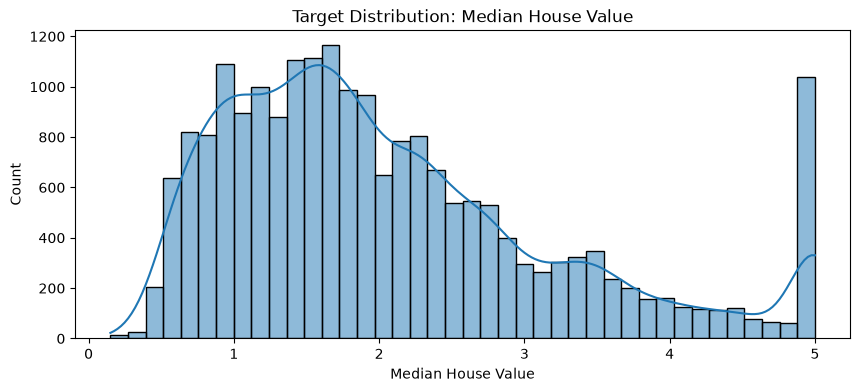

In [53]:
plt.figure(figsize=(10,4))
sns.histplot(df["MedHouseVal"], bins=40, kde=True)
plt.title("Target Distribution: Median House Value")
plt.xlabel("Median House Value")
plt.show()

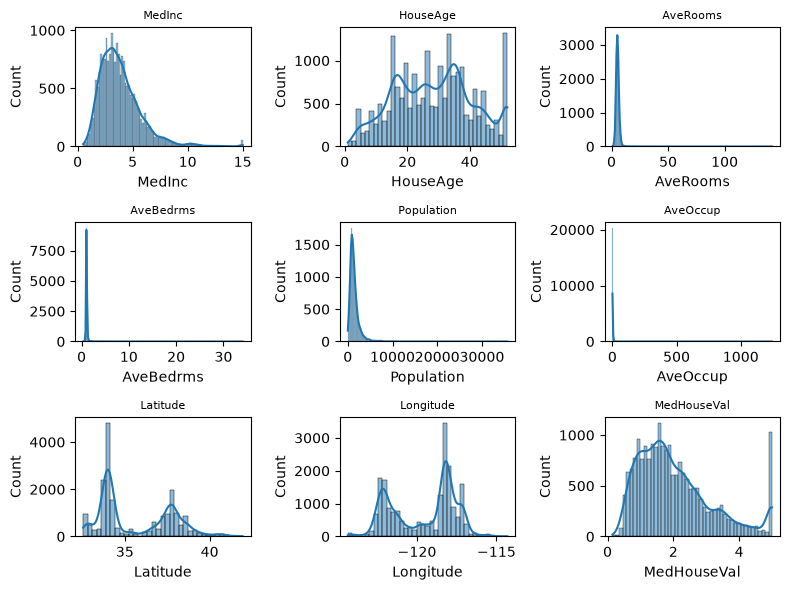

In [56]:
fig, axes = plt.subplots(3, 3, figsize= (8,6))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(col, fontsize=8)
plt.tight_layout()
plt.show()

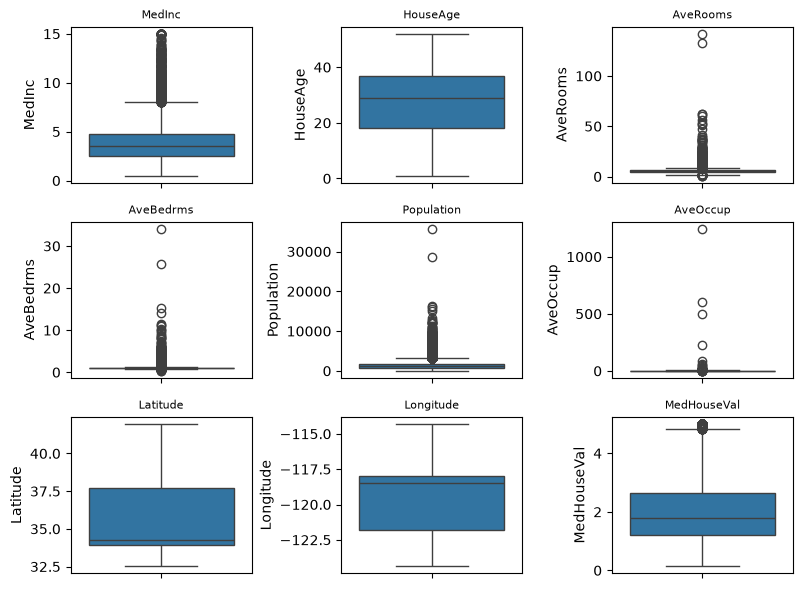

In [58]:
fig, axes = plt.subplots(3, 3, figsize= (8,6))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(df[col], ax=axes[i])
    axes[i].set_title(col, fontsize=8)
    axes[i].set_xlabel("")
plt.tight_layout()
plt.show()

This helps us to identify whether the target is symmetric or skewed or concentrated in specific price ranges.

In [ ]:
from numpy import test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.20, random_state=42)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Here we reserved 80% of the data for model training and 20% for model testing.
Why data split? If we evaluate the model on the same data, we can only check how well the model remembers the training data rather than knowing how well the model will perform on unknown data.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV

#Baseline: Ordinary Least Squares
linear_model = Pipeline([("scaler", StandardScaler()),("model", LinearRegression())])
linear_model.fit(X_train, y_train)

# Ridge: L2 regularization
ridge_pipeline = Pipeline([("scaler", StandardScaler()),("model", Ridge())])

# Lasso: L1 regularization
lasso_pipeline = Pipeline([("scaler", StandardScaler()), ("model", Lasso(max_iter=20000))])

#candidate regularozation strangths
alphavalues = np.logspace(-4, 3, 20)

#select alpha using 5-fold cross validation
ridge_search = GridSearchCV(ridge_pipeline, param_grid={"model__alpha": alphavalues}, scoring="neg_root_mean_squared_error", cv=5, n_jobs = -1)
lasso_search = GridSearchCV(lasso_pipeline, param_grid={"model__alpha": alphavalues}, scoring="neg_root_mean_squared_error", cv=5, n_jobs = -1)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)

models = {"Linear Regression": linear_model, "Ridge regression": ridge_search.best_estimator_, "Lasso Regression": lasso_search.best_estimator_}

print("Best Ridge Alpha:", ridge_search.best_params_["model__alpha"])
print("Best Lasso Alpha:",lasso_search.best_params_["model__alpha"])


In [ ]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results.append({"Model": name, "MAE": mean_absolute_error(y_test, y_pred), "RMSE":np.sqrt(mean_squared_error(y_test, y_pred)), "R2": r2_score(y_test, y_pred)})

results_df = pd.DataFrame(results).set_index("Model")
print(results_df.round(4))


In [ ]:
plt.figure(figsize = (8,6))

for name, y_pred in predictions.items():
    plt.scatter(y_test, y_pred, alpha=0.25, s=12, label=name)
lower = min(y_test.min(), *(p.min() for p in predictions.values()))
upper = max(y_test.max(), *(p.max() for p in predictions.values()))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharex=True, sharey=True)


lower = min(0, float(y_test.min()))
upper = float(y_test.max()) * 1.05

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(
        y_test, y_pred,
        alpha=0.25,
        s=10,
        edgecolors="none",
        rasterized=True
    )

    ax.plot(
        [lower, upper], [lower, upper],
        "k--", linewidth=1.5, label="Perfect prediction"
    )

    
    metrics = results_df.loc[name]

    ax.text(
        0.04, 0.96,
        f"MAE:  {metrics['MAE']:.3f}\n"
        f"RMSE: {metrics['RMSE']:.3f}\n"
        f"R²:    {metrics['R2']:.3f}",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
    )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("Actual House Value")
    ax.grid(alpha=0.2)
    ax.legend(loc="lower right", fontsize=8)

axes[0].set_ylabel("Predicted House Value")

fig.suptitle(
    "House Price Prediction: Model Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



In [ ]:
# Check the selected hyperparameters
print("Best Ridge alpha:", ridge_search.best_params_["model__alpha"])
print("Best Lasso alpha:", lasso_search.best_params_["model__alpha"])

# Show metrics at higher precision
print("\nUnrounded evaluation metrics:")
print(results_df.to_string(float_format=lambda x: f"{x:.8f}"))

# Compare predictions against ordinary Linear Regression
baseline = predictions["Linear Regression"]

for name, pred in predictions.items():
    print(f"\n{name}")
    print("Max absolute prediction difference from Linear:",
          f"{np.max(np.abs(pred - baseline)):.10f}")
    print("Mean absolute prediction difference from Linear:",
          f"{np.mean(np.abs(pred - baseline)):.10f}")

# Compare fitted coefficients
for name in ["Ridge regression", "Lasso Regression"]:
    coef_diff = (
        models[name].named_steps["model"].coef_
        - models["Linear Regression"].named_steps["model"].coef_
    )
    print(f"\n{name} coefficient difference:")
    print(np.round(coef_diff, 8))

In [ ]:
lasso_model = models["Lasso Regression"].named_steps["model"]

coef_table = pd.DataFrame({
    "Feature": X.columns,
    "Linear": models["Linear Regression"]
        .named_steps["model"].coef_,
    "Ridge": models["Ridge regression"]
        .named_steps["model"].coef_,
    "Lasso": lasso_model.coef_
})

coef_table["Lasso_Zero"] = np.isclose(
    coef_table["Lasso"], 0.0
)

print(coef_table.to_string(index=False))
print("\nFeatures eliminated by Lasso:",
      coef_table.loc[coef_table["Lasso_Zero"], "Feature"].tolist())